<a href="https://colab.research.google.com/github/AbdullahAmjad-22/fashion-mnist-cnn-pytorch/blob/main/fashion_mnist_cnn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

In [ ]:
transform = transforms.ToTensor()

train_data = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=transform
)

test_data = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
test_loader = DataLoader(test_data, batch_size=64, shuffle=False)

100%|██████████| 26.4M/26.4M [00:01<00:00, 18.8MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 303kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.60MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 9.16MB/s]


In [ ]:
class CNN(nn.Module):
  def __init__(self):
    super().__init__()

    self.conv1= nn.Conv2d(1, 16, 3, padding=1)
    self.pool= nn.MaxPool2d(2, 2)
    self.conv2= nn.Conv2d(16, 32, 3, padding=1)

    self.fc1= nn.Linear(32*7*7, 128)
    self.fc2= nn.Linear(128,10)

  def forward(self, x):
    x= self.pool(torch.relu(self.conv1(x)))
    x= self.pool(torch.relu(self.conv2(x)))

    x= x.view(x.size(0), -1)

    x= torch.relu(self.fc1(x))
    x=self.fc2(x)

    return x

model = CNN()

In [ ]:
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [ ]:
for epoch in range(5):
  model.train()
  total_loss = 0

  for images, labels in train_loader:
    predictions = model(images)
    loss= loss_fn(predictions, labels)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    total_loss += loss.item()

  print(f"Epoch{epoch+1}, loss:{total_loss/len(train_loader): .4f}")

Epoch1, loss: 0.2092
Epoch2, loss: 0.1947
Epoch3, loss: 0.1805
Epoch4, loss: 0.1666
Epoch5, loss: 0.1517


In [ ]:
model.eval()

correct= 0
total = 0

with torch.no_grad():
  for images, labels in test_loader:
    predictions = model(images)
    predicted_labels = predictions.argmax(dim=1)

    correct += (predicted_labels == labels).sum().item()
    total += labels.size(0)

  accuracy = 100 * correct/total

  print(f"Test Accuracy: {accuracy:.2f}%")

Test Accuracy: 91.57%


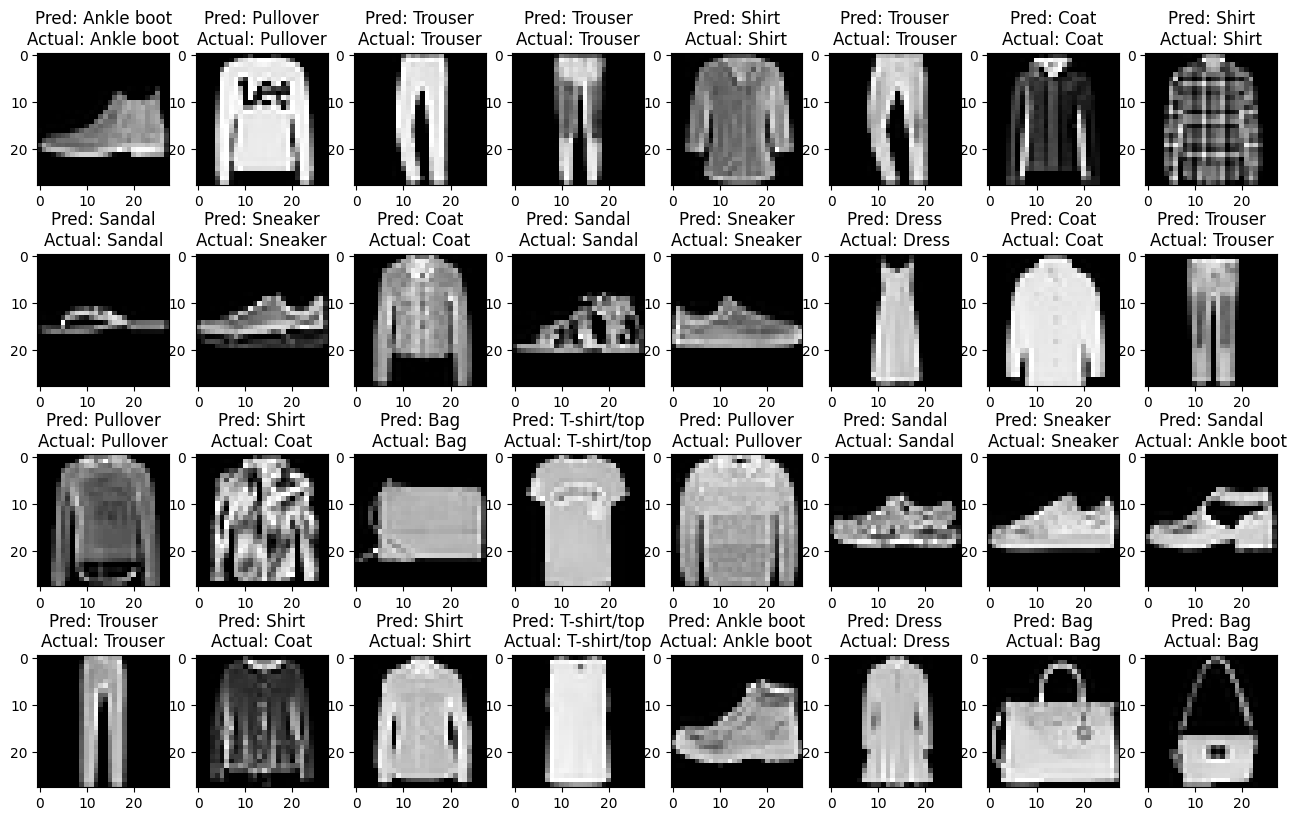

In [ ]:
classes = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

images, labels = next(iter(test_loader))

with torch.no_grad():
  predictions = model(images).argmax(dim=1)

plt.figure(figsize=(16,10))

for i in range(32):
  plt.subplot(4, 8, i+1)
  plt.imshow(images[i].squeeze(), cmap="gray")
  plt.title(f"Pred: {classes[predictions[i]]}\nActual: {classes[labels[i]]}")

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [ ]:
model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
  for images, labels in test_loader:
    outputs = model(images)
    predictions=outputs.argmax(dim=1)

    all_predictions.extend(predictions.numpy())
    all_labels.extend(labels.numpy())

cm = confusion_matrix(all_labels, all_predictions)

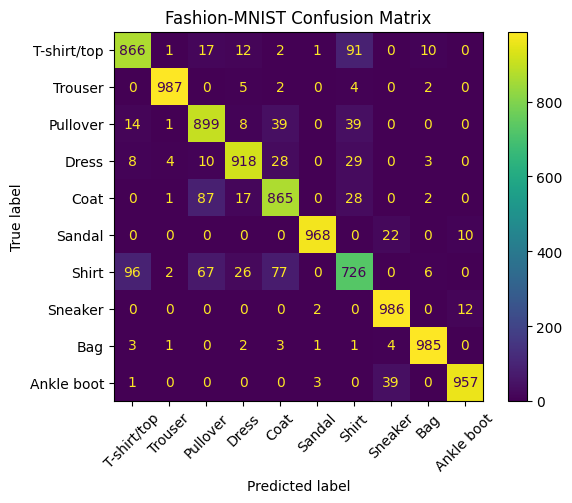

In [ ]:
classes = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)

display.plot(xticks_rotation=45)
plt.title("Fashion-MNIST Confusion Matrix")
plt.show()